# Dia 23 — Python Design Patterns para Data Science

**Data:** 22/11/2026 · **Fase 1 — Python Basics (Dia 23/28)**

Hoje o foco é **arquitetura de código**: como organizar projetos de Data Science/ML para que sejam
reutilizáveis, testáveis e fáceis de estender. Vamos implementar, do zero, seis *design patterns*
clássicos e aplicá-los a fluxos reais de DS/ML:

| # | Pattern | Problema que resolve em DS/ML |
|---|---------|-------------------------------|
| 1 | **Pipeline** | Encadear etapas de pré-processamento (ex.: limpeza de texto para PLN) |
| 2 | **Factory** | Criar estimadores a partir de configuração, sem `if/else` espalhados |
| 3 | **Strategy** | Trocar o algoritmo de escalonamento sem mudar o código cliente |
| 4 | **Observer** | Monitorar métricas durante o treino (logs, histórico, *early stopping*) |
| 5 | **Repository** | Abstrair a origem dos dados (scikit-learn, seaborn, CSV, statsmodels) |
| 6 | **Template Method** | Padronizar o fluxo de um experimento de ML |

> **Dados:** apenas datasets públicos reais — `load_iris`, `load_wine`, `load_breast_cancer`,
> `load_diabetes` (scikit-learn), `tips`, `titanic`, `penguins` (seaborn) e datasets do `statsmodels`.
> O "corpus educacional" de PLN é formado pelas **descrições oficiais (DESCR)** desses datasets —
> textos técnicos reais, didáticos, distribuídos junto com as bibliotecas.

## 0. Setup

Importamos apenas bibliotecas padrão do ecossistema científico. `abc` (Abstract Base Classes) e
`typing.Protocol` serão as ferramentas centrais para definir **interfaces** em Python.

In [1]:
"""Day 23 — Design patterns for Data Science: imports and global settings."""
from __future__ import annotations

import re
import string
import tempfile
import time
import unicodedata
import warnings
from abc import ABC, abstractmethod
from collections import Counter
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Protocol

import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn import datasets as skds
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 120)
print("numpy", np.__version__, "| pandas", pd.__version__, "| seaborn", sns.__version__)

numpy 1.26.4 | pandas 2.3.3 | seaborn 0.13.2


## 1. Pipeline Pattern

### 📘 Conceito
O **Pipeline** (também chamado *Pipes and Filters* ou *Chain of Processing*) organiza um processamento
como uma **sequência de etapas independentes**, em que a saída de uma etapa é a entrada da próxima.
Cada etapa tem **uma única responsabilidade** e a mesma interface (aqui, um método `process`).

**Por que importa em DS?**
- Pré-processamento de texto em PLN é naturalmente sequencial: normalizar → tokenizar → remover
  *stopwords* → filtrar → contar.
- Etapas podem ser **reordenadas, removidas ou testadas isoladamente**.
- O `sklearn.pipeline.Pipeline` é exatamente este padrão — hoje vamos construí-lo **do zero** para
  entender o mecanismo.

```
texto bruto ─▶ [Lowercase] ─▶ [StripAccents] ─▶ [Tokenize] ─▶ [Stopwords] ─▶ [MinLength] ─▶ tokens
```

In [2]:
class PipelineStep(ABC):
    """A single, stateless-by-default processing step.

    Subclasses implement ``process``; optional ``fit`` allows steps that learn
    from data (e.g. a vocabulary filter) to follow the fit/transform contract.
    """

    name: str = "step"

    def fit(self, data: Any) -> "PipelineStep":
        """Learn parameters from data. Default: no-op."""
        return self

    @abstractmethod
    def process(self, data: Any) -> Any:
        """Transform the input and return the output for the next step."""

    def __repr__(self) -> str:
        return f"{self.__class__.__name__}()"


class TextPipeline:
    """Minimal from-scratch pipeline that chains ``PipelineStep`` objects."""

    def __init__(self, steps: list[PipelineStep], verbose: bool = False) -> None:
        if not steps:
            raise ValueError("A pipeline needs at least one step.")
        self.steps = list(steps)
        self.verbose = verbose
        self.timings: dict[str, float] = {}

    def fit(self, data: Any) -> "TextPipeline":
        """Fit each step on the output of the previous (already fitted) steps."""
        for step in self.steps:
            step.fit(data)
            data = step.process(data)
        return self

    def process(self, data: Any) -> Any:
        """Run data through every step in order, recording per-step timings."""
        for step in self.steps:
            start = time.perf_counter()
            data = step.process(data)
            self.timings[repr(step)] = time.perf_counter() - start
            if self.verbose:
                preview = data[:8] if isinstance(data, list) else str(data)[:60]
                print(f"{repr(step):<28} -> {preview}")
        return data

    def add_step(self, step: PipelineStep, position: int | None = None) -> "TextPipeline":
        """Insert a step (fluent interface: returns self)."""
        self.steps.insert(len(self.steps) if position is None else position, step)
        return self

    def __repr__(self) -> str:
        return " -> ".join(repr(s) for s in self.steps)

### 🔧 Etapas concretas de pré-processamento de texto
Cada classe abaixo faz **uma coisa só**. Note que todas respeitam a mesma interface — isso é o que
permite combiná-las livremente (princípio *Open/Closed*: aberto para extensão, fechado para modificação).

In [3]:
ENGLISH_STOPWORDS = frozenset(
    """a an the and or but if of at by for with about against between into through during
    before after above below to from up down in out on off over under again further then once
    here there when where why how all any both each few more most other some such no nor not only
    own same so than too very s t can will just don should now is are was were be been being have
    has had having do does did doing i me my we our you your he him his she her it its they them
    their what which who whom this that these those am as until while also may per""".split()
)


class Lowercase(PipelineStep):
    """Lower-case the whole document."""

    def process(self, data: str) -> str:
        return data.lower()


class StripAccents(PipelineStep):
    """Remove diacritics (useful for PT/EN mixed corpora)."""

    def process(self, data: str) -> str:
        nfkd = unicodedata.normalize("NFKD", data)
        return "".join(ch for ch in nfkd if not unicodedata.combining(ch))


class RemoveNumbersAndPunctuation(PipelineStep):
    """Replace digits and punctuation with spaces."""

    _table = str.maketrans({c: " " for c in string.punctuation + string.digits})

    def process(self, data: str) -> str:
        return data.translate(self._table)


class Tokenize(PipelineStep):
    """Whitespace/regex tokenizer that keeps alphabetic tokens."""

    def process(self, data: str) -> list[str]:
        return re.findall(r"[a-z]+", data)


class RemoveStopwords(PipelineStep):
    """Drop function words from a token list."""

    def __init__(self, stopwords: frozenset[str] = ENGLISH_STOPWORDS) -> None:
        self.stopwords = stopwords

    def process(self, data: list[str]) -> list[str]:
        return [t for t in data if t not in self.stopwords]


class MinLength(PipelineStep):
    """Keep tokens with at least ``n`` characters."""

    def __init__(self, n: int = 3) -> None:
        self.n = n

    def process(self, data: list[str]) -> list[str]:
        return [t for t in data if len(t) >= self.n]

    def __repr__(self) -> str:
        return f"MinLength(n={self.n})"


class SimpleStemmer(PipelineStep):
    """Very light suffix stripper (didactic; not a Porter stemmer)."""

    SUFFIXES = ("ations", "ation", "ings", "ing", "ies", "es", "ed", "ly", "s")

    def process(self, data: list[str]) -> list[str]:
        out = []
        for tok in data:
            for suf in self.SUFFIXES:
                if tok.endswith(suf) and len(tok) - len(suf) >= 4:
                    tok = tok[: -len(suf)]
                    break
            out.append(tok)
        return out

### 📚 Corpus educacional real
Usamos como corpus as **descrições oficiais** dos datasets do scikit-learn e do statsmodels. São
textos técnicos reais, escritos para ensinar sobre cada base — um bom exemplo de **gênero textual
acadêmico/didático**, com vocabulário especializado (termos estatísticos, biomédicos etc.).

In [4]:
def build_educational_corpus() -> pd.DataFrame:
    """Collect real dataset documentation texts from scikit-learn and statsmodels."""
    docs = []
    for name, loader in {
        "iris": skds.load_iris, "wine": skds.load_wine,
        "breast_cancer": skds.load_breast_cancer, "diabetes": skds.load_diabetes,
        "digits": skds.load_digits, "linnerud": skds.load_linnerud,
    }.items():
        docs.append({"source": "sklearn", "doc_id": name, "text": loader().DESCR})
    for name in ["longley", "star98", "anes96", "spector", "macrodata", "co2", "sunspots"]:
        mod = getattr(sm.datasets, name)
        text = " ".join(str(getattr(mod, attr, "")) for attr in ("TITLE", "DESCRSHORT", "DESCRLONG", "NOTE"))
        docs.append({"source": "statsmodels", "doc_id": name, "text": text})
    df = pd.DataFrame(docs)
    df["n_chars"] = df["text"].str.len()
    return df


corpus = build_educational_corpus()
print(corpus.shape)
corpus[["source", "doc_id", "n_chars"]]

(13, 4)


,source,doc_id,n_chars
0,sklearn,iris,2656
1,sklearn,wine,3367
2,sklearn,breast_cancer,4794
3,sklearn,diabetes,1455
4,sklearn,digits,2007
5,sklearn,linnerud,704
6,statsmodels,longley,533
7,statsmodels,star98,2090
8,statsmodels,anes96,2779
9,statsmodels,spector,607


In [5]:
text_pipeline = TextPipeline(
    steps=[Lowercase(), StripAccents(), RemoveNumbersAndPunctuation(), Tokenize(),
           RemoveStopwords(), MinLength(n=3)],
    verbose=True,
)
print("Pipeline:", text_pipeline, "\n")
iris_tokens = text_pipeline.process(corpus.loc[corpus.doc_id == "iris", "text"].iloc[0])
print(f"\n{len(iris_tokens)} tokens after preprocessing")

Pipeline: Lowercase() -> StripAccents() -> RemoveNumbersAndPunctuation() -> Tokenize() -> RemoveStopwords() -> MinLength(n=3) 

Lowercase()                  -> .. _iris_dataset:

iris plants dataset
--------------------

StripAccents()               -> .. _iris_dataset:

iris plants dataset
--------------------

RemoveNumbersAndPunctuation() ->     iris dataset 

iris plants dataset
                    

Tokenize()                   -> ['iris', 'dataset', 'iris', 'plants', 'dataset', 'data', 'set', 'characteristics']
RemoveStopwords()            -> ['iris', 'dataset', 'iris', 'plants', 'dataset', 'data', 'set', 'characteristics']
MinLength(n=3)               -> ['iris', 'dataset', 'iris', 'plants', 'dataset', 'data', 'set', 'characteristics']

198 tokens after preprocessing


### 🔁 Extensibilidade: inserindo uma etapa sem alterar as outras
Graças à interface comum, adicionar um *stemmer* é uma linha. Em seguida aplicamos o pipeline ao
corpus inteiro e medimos **riqueza lexical** (*type-token ratio*, TTR) — métrica clássica da
Linguística para comparar textos.

In [6]:
text_pipeline.verbose = False
text_pipeline.add_step(SimpleStemmer())
print("Extended pipeline:", text_pipeline)

corpus["tokens"] = corpus["text"].apply(text_pipeline.process)
corpus["n_tokens"] = corpus["tokens"].str.len()
corpus["n_types"] = corpus["tokens"].apply(lambda t: len(set(t)))
corpus["ttr"] = (corpus["n_types"] / corpus["n_tokens"]).round(3)
print(corpus[["source", "doc_id", "n_tokens", "n_types", "ttr"]].sort_values("n_tokens", ascending=False).to_string(index=False))

Extended pipeline: Lowercase() -> StripAccents() -> RemoveNumbersAndPunctuation() -> Tokenize() -> RemoveStopwords() -> MinLength(n=3) -> SimpleStemmer()
     source        doc_id  n_tokens  n_types   ttr
    sklearn breast_cancer       344      168 0.488
    sklearn          wine       233      143 0.614
    sklearn          iris       198      131 0.662
    sklearn        digits       175      130 0.743
statsmodels        star98       172      103 0.599
    sklearn      diabetes       144      103 0.715
statsmodels     macrodata       130       65 0.500
statsmodels        anes96       125       70 0.560
statsmodels           co2       104       68 0.654
    sklearn      linnerud        64       47 0.734
statsmodels       spector        51       31 0.608
statsmodels       longley        43       34 0.791
statsmodels      sunspots        36       18 0.500


In [7]:
all_tokens = Counter(tok for toks in corpus["tokens"] for tok in toks)
print("Top-15 content stems in the educational corpus:")
print(pd.DataFrame(all_tokens.most_common(15), columns=["stem", "freq"]).to_string(index=False))
print("\nPer-step timings (last call, seconds):")
print({k: round(v, 6) for k, v in text_pipeline.timings.items()})

Top-15 content stems in the educational corpus:
     stem  freq
     data    40
   number    36
  dataset    24
     clas    19
  variabl    18
     mean    17
     year    15
 standard    13
    worst    13
      set    11
    total    11
    error    11
  student    11
attribute    10
 attribut     9

Per-step timings (last call, seconds):
{'Lowercase()': 0.0, 'StripAccents()': 1.6e-05, 'RemoveNumbersAndPunctuation()': 3e-06, 'Tokenize()': 7e-06, 'RemoveStopwords()': 3e-06, 'MinLength(n=3)': 1e-06, 'SimpleStemmer()': 2.1e-05}


> **Nota de linguista:** o TTR é sensível ao tamanho do texto (textos maiores tendem a TTR menor),
> então comparações justas exigem normalização (ex.: MATTR, ou amostras de tamanho fixo). O padrão
> Pipeline facilita testar essas variações: basta trocar ou adicionar uma etapa.

## 2. Factory Pattern

### 📘 Conceito
O **Factory** centraliza a **criação de objetos**: o código cliente pede "um modelo do tipo X com
estes parâmetros" e a fábrica decide **qual classe instanciar**. Isso evita cadeias de `if/elif`
espalhadas pelo projeto.

**Por que importa em DS?**
- Experimentos são guiados por **configuração** (YAML/JSON/dict): `{"model": "random_forest", ...}`.
- Novos modelos são adicionados por **registro**, sem tocar no código que os usa.
- Facilita *grid* de experimentos e reprodutibilidade (mesma config → mesmo objeto).

Implementaremos uma variação moderna: **Factory com registro via decorator**.

In [8]:
class ModelFactory:
    """Registry-based factory for scikit-learn estimators."""

    _registry: dict[str, Callable[..., Any]] = {}
    _defaults: dict[str, dict[str, Any]] = {}

    @classmethod
    def register(cls, name: str, **defaults: Any) -> Callable:
        """Decorator that registers a builder function under ``name``."""
        def decorator(builder: Callable[..., Any]) -> Callable[..., Any]:
            if name in cls._registry:
                raise KeyError(f"Model '{name}' already registered.")
            cls._registry[name] = builder
            cls._defaults[name] = defaults
            return builder
        return decorator

    @classmethod
    def create(cls, name: str, **params: Any) -> Any:
        """Build an estimator; user params override registered defaults."""
        if name not in cls._registry:
            raise ValueError(f"Unknown model '{name}'. Available: {cls.available()}")
        merged = {**cls._defaults[name], **params}
        return cls._registry[name](**merged)

    @classmethod
    def from_config(cls, config: dict[str, Any]) -> Any:
        """Build an estimator from a config dict: {'type': ..., 'params': {...}}."""
        return cls.create(config["type"], **config.get("params", {}))

    @classmethod
    def available(cls) -> list[str]:
        return sorted(cls._registry)


@ModelFactory.register("logistic_regression", max_iter=5000, random_state=RANDOM_STATE)
def _build_logreg(**params: Any) -> LogisticRegression:
    return LogisticRegression(**params)


@ModelFactory.register("random_forest", n_estimators=200, random_state=RANDOM_STATE)
def _build_rf(**params: Any) -> RandomForestClassifier:
    return RandomForestClassifier(**params)


@ModelFactory.register("svm", kernel="rbf", probability=False, random_state=RANDOM_STATE)
def _build_svm(**params: Any) -> SVC:
    return SVC(**params)


print("Registered models:", ModelFactory.available())
print(ModelFactory.create("svm", C=2.0))

Registered models: ['logistic_regression', 'random_forest', 'svm']
SVC(C=2.0, probability=False, random_state=42)


### 🧪 Exemplo prático: experimentos guiados por configuração
Uma lista de configurações (como viria de um arquivo YAML) gera os modelos. Avaliamos com
validação cruzada estratificada (5 *folds*) no dataset **breast_cancer**. Como SVM e Regressão
Logística são sensíveis à escala, envolvemos esses modelos em um `make_pipeline` com `StandardScaler`.

In [9]:
from sklearn.pipeline import make_pipeline

experiment_configs = [
    {"type": "logistic_regression", "params": {"C": 1.0}, "scale": True},
    {"type": "logistic_regression", "params": {"C": 0.1}, "scale": True},
    {"type": "random_forest", "params": {"max_depth": 5}, "scale": False},
    {"type": "svm", "params": {"C": 1.0}, "scale": True},
    {"type": "svm", "params": {"C": 10.0, "gamma": "scale"}, "scale": True},
]

X_bc, y_bc = skds.load_breast_cancer(return_X_y=True)
rows = []
for cfg in experiment_configs:
    model = ModelFactory.from_config(cfg)
    if cfg["scale"]:
        model = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(model, X_bc, y_bc, cv=5, scoring="accuracy")
    rows.append({"model": cfg["type"], "params": cfg["params"],
                 "cv_acc_mean": scores.mean().round(4), "cv_acc_std": scores.std().round(4)})
factory_results = pd.DataFrame(rows)
factory_results

,model,params,cv_acc_mean,cv_acc_std
0,logistic_regression,{'C': 1.0},0.9807,0.0065
1,logistic_regression,{'C': 0.1},0.9772,0.0070
2,random_forest,{'max_depth': 5},0.9596,0.0212
3,svm,{'C': 1.0},0.9736,0.0147
4,svm,"{'C': 10.0, 'gamma': 'scale'}",0.9772,0.0089


In [10]:
# Extending the factory: a new model is one decorated function — no client code changes.
@ModelFactory.register("sgd_logistic", loss="log_loss", max_iter=2000, random_state=RANDOM_STATE)
def _build_sgd(**params: Any) -> SGDClassifier:
    return SGDClassifier(**params)


print("Registered models:", ModelFactory.available())
try:
    ModelFactory.create("xgboost")
except ValueError as err:
    print("Expected error ->", err)

Registered models: ['logistic_regression', 'random_forest', 'sgd_logistic', 'svm']
Expected error -> Unknown model 'xgboost'. Available: ['logistic_regression', 'random_forest', 'sgd_logistic', 'svm']


> **Leitura dos resultados:** as médias acima vêm de uma única validação cruzada de 5 *folds*; as
> diferenças entre modelos são pequenas frente ao desvio-padrão, portanto **não** constituem um
> *ranking* definitivo. O objetivo aqui é a arquitetura, não a escolha do melhor modelo.

## 3. Strategy Pattern

### 📘 Conceito
O **Strategy** define uma **família de algoritmos intercambiáveis** atrás de uma interface comum.
O objeto que usa a estratégia (o *contexto*) não sabe qual algoritmo concreto está rodando — ele
apenas chama a interface.

**Diferença para Factory:** Factory trata de **criar** objetos; Strategy trata de **trocar
comportamento** em tempo de execução.

**Exemplo em DS:** escalonamento de *features*. `StandardScaler`, `MinMaxScaler` e `RobustScaler`
resolvem o mesmo problema de formas diferentes — e a escolha certa depende da distribuição dos
dados (ex.: presença de *outliers*).

Usaremos `typing.Protocol` (tipagem estrutural, *duck typing* verificável) para a interface.

In [11]:
class ScalingStrategy(Protocol):
    """Structural interface: anything with fit_transform/transform and a name."""

    name: str

    def fit_transform(self, X: np.ndarray) -> np.ndarray: ...
    def transform(self, X: np.ndarray) -> np.ndarray: ...


class _SklearnScalerStrategy:
    """Adapter wrapping a scikit-learn scaler behind the strategy interface."""

    name = "base"
    _scaler_cls: type = StandardScaler

    def __init__(self, **params: Any) -> None:
        self._scaler = self._scaler_cls(**params)

    def fit_transform(self, X: np.ndarray) -> np.ndarray:
        return self._scaler.fit_transform(X)

    def transform(self, X: np.ndarray) -> np.ndarray:
        return self._scaler.transform(X)


class StandardStrategy(_SklearnScalerStrategy):
    """z-score: (x - mean) / std. Sensitive to outliers."""
    name, _scaler_cls = "standard", StandardScaler


class MinMaxStrategy(_SklearnScalerStrategy):
    """Rescale to [0, 1]. Very sensitive to extreme values."""
    name, _scaler_cls = "minmax", MinMaxScaler


class RobustStrategy(_SklearnScalerStrategy):
    """(x - median) / IQR. Robust to outliers."""
    name, _scaler_cls = "robust", RobustScaler


class LogStandardStrategy:
    """Custom strategy written from scratch: log1p then z-score (for skewed, non-negative data)."""

    name = "log_standard"

    def __init__(self) -> None:
        self.mean_: np.ndarray | None = None
        self.std_: np.ndarray | None = None

    def fit_transform(self, X: np.ndarray) -> np.ndarray:
        Z = np.log1p(np.clip(X, 0, None))
        self.mean_, self.std_ = Z.mean(axis=0), Z.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return (Z - self.mean_) / self.std_

    def transform(self, X: np.ndarray) -> np.ndarray:
        if self.mean_ is None:
            raise RuntimeError("Call fit_transform first.")
        return (np.log1p(np.clip(X, 0, None)) - self.mean_) / self.std_

### 🎛️ O contexto: um pré-processador que recebe a estratégia
O `Preprocessor` respeita a regra de ouro contra **vazamento de dados** (*data leakage*): a
estratégia é ajustada **somente no treino** e apenas aplicada no teste. Trocar de estratégia é
um único método: `set_strategy`.

In [12]:
class Preprocessor:
    """Context object that delegates scaling to an interchangeable strategy."""

    def __init__(self, strategy: ScalingStrategy) -> None:
        self.strategy = strategy

    def set_strategy(self, strategy: ScalingStrategy) -> None:
        self.strategy = strategy

    def fit_transform(self, X_train: np.ndarray) -> np.ndarray:
        return self.strategy.fit_transform(X_train)

    def transform(self, X_test: np.ndarray) -> np.ndarray:
        return self.strategy.transform(X_test)


# Seaborn tips: total_bill and tip are right-skewed with a few large values.
tips = sns.load_dataset("tips")
X_tips = tips[["total_bill", "tip", "size"]].to_numpy(dtype=float)
prep = Preprocessor(StandardStrategy())
summary = {}
for strat in [StandardStrategy(), MinMaxStrategy(), RobustStrategy(), LogStandardStrategy()]:
    prep.set_strategy(strat)
    Z = prep.fit_transform(X_tips)
    summary[strat.name] = {"min_total_bill": Z[:, 0].min(), "max_total_bill": Z[:, 0].max(),
                           "median_total_bill": np.median(Z[:, 0]), "std_total_bill": Z[:, 0].std()}
pd.DataFrame(summary).T.round(3)

,min_total_bill,max_total_bill,median_total_bill,std_total_bill
standard,-1.882,3.492,-0.224,1.000
minmax,0.000,1.000,0.308,0.186
robust,-1.366,3.063,-0.000,0.824
log_standard,-3.751,2.422,-0.038,1.000


### 🧪 Exemplo prático: a estratégia afeta o modelo?
Comparamos as estratégias no dataset **wine** (13 *features* químicas com escalas muito diferentes)
treinando a mesma Regressão Logística. Tudo que muda é o objeto de estratégia.

In [13]:
X_wine, y_wine = skds.load_wine(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=RANDOM_STATE)

strategy_rows = []
for strat in [None, StandardStrategy(), MinMaxStrategy(), RobustStrategy(), LogStandardStrategy()]:
    if strat is None:
        Ztr, Zte, label = Xtr, Xte, "no_scaling"
    else:
        prep.set_strategy(strat)
        Ztr, Zte, label = prep.fit_transform(Xtr), prep.transform(Xte), strat.name
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        clf = LogisticRegression(max_iter=200, random_state=RANDOM_STATE).fit(Ztr, ytr)
    converged = not any("converge" in str(w.message) for w in caught)
    strategy_rows.append({"strategy": label, "n_iter": int(clf.n_iter_.max()), "converged": converged,
                          "test_accuracy": round(accuracy_score(yte, clf.predict(Zte)), 4)})
pd.DataFrame(strategy_rows)

,strategy,n_iter,converged,test_accuracy
0,no_scaling,200,False,0.9815
1,standard,17,True,0.9815
2,minmax,29,True,1.0000
3,robust,13,True,0.9815
4,log_standard,15,True,0.9815


> **Observação:** sem escalonamento, o otimizador precisa de mais iterações (ou nem converge no
> limite de 200), pois *features* como `proline` (centenas) dominam as demais. Com qualquer
> estratégia, a convergência é bem mais rápida. Resultado de **um único *split***, ilustrativo.

## 4. Observer Pattern

### 📘 Conceito
O **Observer** (ou *Publish/Subscribe*) define uma relação **um-para-muitos**: um objeto *sujeito*
(*subject*) notifica automaticamente vários *observadores* quando um evento acontece. O sujeito não
conhece os detalhes dos observadores — só a interface `update(event, payload)`.

**Por que importa em ML?** É exatamente o mecanismo de **callbacks** do Keras/PyTorch Lightning:
- um observador imprime logs,
- outro guarda o histórico de métricas,
- outro decide parar o treino cedo (*early stopping*),
- outro salva o melhor modelo (*checkpoint*).

O loop de treino fica **limpo**, e o monitoramento vira "plug-and-play".

In [14]:
class TrainingObserver(ABC):
    """Interface for anything that wants to react to training events."""

    def on_train_begin(self, trainer: "ObservableTrainer") -> None: ...
    def on_epoch_end(self, trainer: "ObservableTrainer", epoch: int, metrics: dict[str, float]) -> None: ...
    def on_train_end(self, trainer: "ObservableTrainer") -> None: ...


class ObservableTrainer:
    """Subject: an incremental trainer (``partial_fit``) that notifies observers each epoch."""

    def __init__(self, model: Any, classes: np.ndarray, max_epochs: int = 50) -> None:
        self.model = model
        self.classes = classes
        self.max_epochs = max_epochs
        self.stop_training = False
        self._observers: list[TrainingObserver] = []

    def attach(self, observer: TrainingObserver) -> "ObservableTrainer":
        self._observers.append(observer)
        return self

    def detach(self, observer: TrainingObserver) -> None:
        self._observers.remove(observer)

    def _notify(self, method: str, *args: Any) -> None:
        for obs in self._observers:
            getattr(obs, method)(self, *args)

    def fit(self, X_tr, y_tr, X_val, y_val, rng_seed: int = RANDOM_STATE) -> "ObservableTrainer":
        rng = np.random.default_rng(rng_seed)
        self._notify("on_train_begin")
        for epoch in range(1, self.max_epochs + 1):
            idx = rng.permutation(len(X_tr))
            self.model.partial_fit(X_tr[idx], y_tr[idx], classes=self.classes)
            metrics = {
                "train_loss": log_loss(y_tr, self.model.predict_proba(X_tr), labels=self.classes),
                "val_loss": log_loss(y_val, self.model.predict_proba(X_val), labels=self.classes),
                "val_acc": accuracy_score(y_val, self.model.predict(X_val)),
            }
            self._notify("on_epoch_end", epoch, metrics)
            if self.stop_training:
                break
        self._notify("on_train_end")
        return self

### 👀 Observadores concretos
Quatro observadores independentes. Nenhum deles conhece os outros, e o *trainer* não conhece
nenhum detalhe deles.

In [15]:
class ConsoleLogger(TrainingObserver):
    """Print metrics every ``every`` epochs."""

    def __init__(self, every: int = 5) -> None:
        self.every = every

    def on_train_begin(self, trainer):
        print(f"Training {trainer.model.__class__.__name__} for up to {trainer.max_epochs} epochs")

    def on_epoch_end(self, trainer, epoch, metrics):
        if epoch == 1 or epoch % self.every == 0:
            print(f"epoch {epoch:>3} | " + " | ".join(f"{k}={v:.4f}" for k, v in metrics.items()))

    def on_train_end(self, trainer):
        print("Training finished.")


class HistoryRecorder(TrainingObserver):
    """Store every epoch's metrics in a DataFrame-friendly list."""

    def __init__(self) -> None:
        self.records: list[dict[str, float]] = []

    def on_epoch_end(self, trainer, epoch, metrics):
        self.records.append({"epoch": epoch, **metrics})

    @property
    def history(self) -> pd.DataFrame:
        return pd.DataFrame(self.records)


class EarlyStopping(TrainingObserver):
    """Stop when ``monitor`` does not improve by ``min_delta`` for ``patience`` epochs."""

    def __init__(self, monitor: str = "val_loss", patience: int = 5, min_delta: float = 1e-4) -> None:
        self.monitor, self.patience, self.min_delta = monitor, patience, min_delta
        self.best, self.wait, self.stopped_epoch = np.inf, 0, None

    def on_epoch_end(self, trainer, epoch, metrics):
        value = metrics[self.monitor]
        if value < self.best - self.min_delta:
            self.best, self.wait = value, 0
        else:
            self.wait += 1
            if self.wait >= self.patience:
                trainer.stop_training, self.stopped_epoch = True, epoch
                print(f"EarlyStopping: no {self.monitor} improvement for {self.patience} epochs (epoch {epoch}).")


class BestModelCheckpoint(TrainingObserver):
    """Keep an in-memory deep copy of the model with the best validation accuracy."""

    def __init__(self) -> None:
        self.best_acc, self.best_epoch, self.best_model = -np.inf, None, None

    def on_epoch_end(self, trainer, epoch, metrics):
        if metrics["val_acc"] > self.best_acc:
            import copy
            self.best_acc, self.best_epoch = metrics["val_acc"], epoch
            self.best_model = copy.deepcopy(trainer.model)

### 🧪 Exemplo prático: monitorando um `SGDClassifier` no breast_cancer
Usamos `partial_fit` (treino incremental, época a época). Os dados são escalonados com a
**StandardStrategy** do Strategy Pattern — os padrões se combinam naturalmente.

In [16]:
Xtr, Xval, ytr, yval = train_test_split(X_bc, y_bc, test_size=0.25, stratify=y_bc, random_state=RANDOM_STATE)
scaler_strategy = StandardStrategy()
Xtr_s, Xval_s = scaler_strategy.fit_transform(Xtr), scaler_strategy.transform(Xval)

history_obs = HistoryRecorder()
early_stop = EarlyStopping(monitor="val_loss", patience=5, min_delta=1e-3)
checkpoint = BestModelCheckpoint()
sgd = ModelFactory.create("sgd_logistic", alpha=1e-3, learning_rate="constant", eta0=0.01)

trainer = (ObservableTrainer(sgd, classes=np.unique(y_bc), max_epochs=60)
           .attach(ConsoleLogger(every=5)).attach(history_obs)
           .attach(early_stop).attach(checkpoint))
trainer.fit(Xtr_s, ytr, Xval_s, yval)
print(f"\nBest val_acc={checkpoint.best_acc:.4f} at epoch {checkpoint.best_epoch}; "
      f"stopped at epoch {early_stop.stopped_epoch}")

Training SGDClassifier for up to 60 epochs
epoch   1 | train_loss=0.1334 | val_loss=0.1538 | val_acc=0.9580
epoch   5 | train_loss=0.0805 | val_loss=0.0979 | val_acc=0.9860
epoch  10 | train_loss=0.0692 | val_loss=0.0854 | val_acc=0.9790
epoch  15 | train_loss=0.0643 | val_loss=0.0798 | val_acc=0.9790


epoch  20 | train_loss=0.0614 | val_loss=0.0764 | val_acc=0.9790
epoch  25 | train_loss=0.0594 | val_loss=0.0740 | val_acc=0.9790


epoch  30 | train_loss=0.0579 | val_loss=0.0723 | val_acc=0.9790
epoch  35 | train_loss=0.0567 | val_loss=0.0707 | val_acc=0.9790
epoch  40 | train_loss=0.0558 | val_loss=0.0698 | val_acc=0.9790
EarlyStopping: no val_loss improvement for 5 epochs (epoch 40).
Training finished.

Best val_acc=0.9860 at epoch 4; stopped at epoch 40


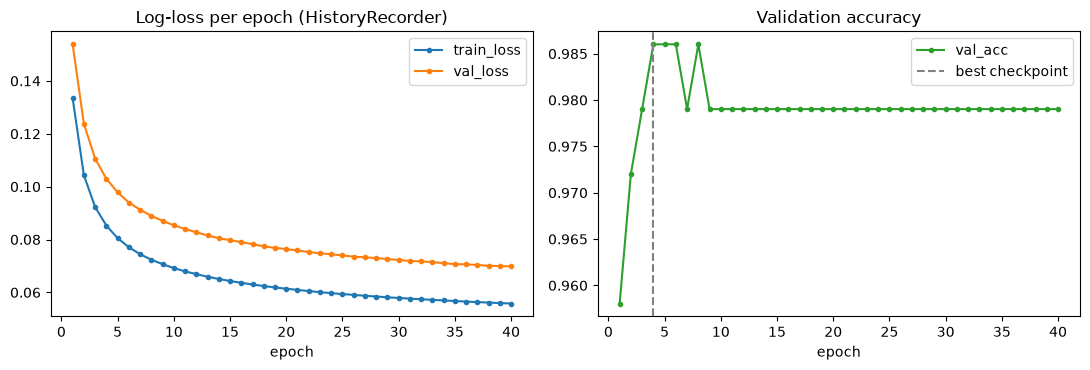

,epoch,train_loss,val_loss,val_acc
35,36,0.056526,0.070628,0.979021
36,37,0.056331,0.070369,0.979021
37,38,0.056154,0.070076,0.979021
38,39,0.055963,0.069968,0.979021
39,40,0.055789,0.069812,0.979021


In [17]:
import matplotlib.pyplot as plt

hist = history_obs.history
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0], marker="o", ms=3)
axes[0].set_title("Log-loss per epoch (HistoryRecorder)")
hist.plot(x="epoch", y="val_acc", ax=axes[1], color="tab:green", marker="o", ms=3, legend=False)
axes[1].axvline(checkpoint.best_epoch, ls="--", color="gray", label="best checkpoint")
axes[1].set_title("Validation accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()
hist.tail()

> **Nota:** o conjunto de validação foi usado tanto para *early stopping* quanto para escolher o
> *checkpoint*; portanto `best_acc` é otimista. Em um projeto real, reserve um **conjunto de teste**
> separado para a estimativa final.

## 5. Repository Pattern

### 📘 Conceito
O **Repository** cria uma **camada de acesso a dados**: o resto do código pede
`repo.get("penguins")` e recebe um `DataFrame`, sem saber se os dados vieram de um CSV, de uma API,
de um banco SQL ou de uma biblioteca.

**Benefícios em DS:**
- Trocar a fonte (CSV local → *data lake*) sem reescrever análises.
- Ponto único para **cache**, **validação de schema** e **log de proveniência**.
- Testes ficam simples: basta um repositório *fake* em memória.

In [18]:
@dataclass
class DatasetRecord:
    """Data plus provenance metadata returned by every repository."""

    name: str
    data: pd.DataFrame
    source: str
    target: str | None = None
    meta: dict[str, Any] = field(default_factory=dict)

    @property
    def shape(self) -> tuple[int, int]:
        return self.data.shape


class DatasetRepository(ABC):
    """Abstract data-access layer."""

    source: str = "abstract"

    @abstractmethod
    def list_datasets(self) -> list[str]:
        """Names this repository can serve."""

    @abstractmethod
    def _load(self, name: str) -> DatasetRecord:
        """Source-specific loading logic."""

    def get(self, name: str) -> DatasetRecord:
        if name not in self.list_datasets():
            raise KeyError(f"{self.source} repository has no dataset '{name}'.")
        return self._load(name)


class SklearnRepository(DatasetRepository):
    """Serve scikit-learn built-in datasets as DataFrames with a 'target' column."""

    source = "sklearn"
    _loaders = {"iris": skds.load_iris, "wine": skds.load_wine,
                "breast_cancer": skds.load_breast_cancer, "diabetes": skds.load_diabetes}

    def list_datasets(self) -> list[str]:
        return list(self._loaders)

    def _load(self, name: str) -> DatasetRecord:
        bunch = self._loaders[name](as_frame=True)
        return DatasetRecord(name, bunch.frame.copy(), self.source, target="target",
                             meta={"n_features": len(bunch.feature_names)})


class SeabornRepository(DatasetRepository):
    """Serve seaborn example datasets (downloaded once, then cached by seaborn)."""

    source = "seaborn"
    _targets = {"tips": "tip", "titanic": "survived", "penguins": "species"}

    def list_datasets(self) -> list[str]:
        return list(self._targets)

    def _load(self, name: str) -> DatasetRecord:
        return DatasetRecord(name, sns.load_dataset(name), self.source, target=self._targets[name])


class StatsmodelsRepository(DatasetRepository):
    """Serve statsmodels datasets (bundled with the library, no download)."""

    source = "statsmodels"
    _names = {"longley": "TOTEMP", "spector": "GRADE", "star98": None}

    def list_datasets(self) -> list[str]:
        return list(self._names)

    def _load(self, name: str) -> DatasetRecord:
        data = getattr(sm.datasets, name).load_pandas().data
        return DatasetRecord(name, data, self.source, target=self._names[name],
                             meta={"title": getattr(sm.datasets, name).TITLE})


class CSVRepository(DatasetRepository):
    """Serve every ``*.csv`` file in a directory."""

    source = "csv"

    def __init__(self, root: Path, targets: dict[str, str] | None = None) -> None:
        self.root, self.targets = Path(root), targets or {}

    def list_datasets(self) -> list[str]:
        return sorted(p.stem for p in self.root.glob("*.csv"))

    def _load(self, name: str) -> DatasetRecord:
        path = self.root / f"{name}.csv"
        return DatasetRecord(name, pd.read_csv(path), self.source, target=self.targets.get(name),
                             meta={"path": str(path)})

### 🧱 Decorando repositórios: cache e catálogo unificado
Um `CachedRepository` envolve qualquer repositório (padrão *Decorator/Proxy*) e um `DataCatalog`
agrega vários repositórios sob nomes qualificados `fonte/dataset`.

In [19]:
class CachedRepository(DatasetRepository):
    """Wrap another repository with an in-memory cache and hit/miss counters."""

    def __init__(self, inner: DatasetRepository) -> None:
        self.inner, self.source = inner, inner.source
        self._cache: dict[str, DatasetRecord] = {}
        self.hits = self.misses = 0

    def list_datasets(self) -> list[str]:
        return self.inner.list_datasets()

    def _load(self, name: str) -> DatasetRecord:
        if name in self._cache:
            self.hits += 1
        else:
            self.misses += 1
            self._cache[name] = self.inner.get(name)
        rec = self._cache[name]
        return DatasetRecord(rec.name, rec.data.copy(), rec.source, rec.target, dict(rec.meta))


class DataCatalog:
    """Single entry point: catalog.get('seaborn/penguins')."""

    def __init__(self, *repos: DatasetRepository) -> None:
        self.repos = {r.source: r for r in repos}

    def get(self, qualified_name: str) -> DatasetRecord:
        source, name = qualified_name.split("/", 1)
        return self.repos[source].get(name)

    def overview(self) -> pd.DataFrame:
        rows = []
        for src, repo in self.repos.items():
            for name in repo.list_datasets():
                rec = repo.get(name)
                rows.append({"dataset": f"{src}/{name}", "rows": rec.shape[0],
                             "cols": rec.shape[1], "target": rec.target})
        return pd.DataFrame(rows)

In [20]:
# Write two real datasets to CSV in a temporary directory to exercise CSVRepository.
tmp_dir = Path(tempfile.mkdtemp(prefix="day23_repo_"))
sns.load_dataset("penguins").dropna().to_csv(tmp_dir / "penguins_clean.csv", index=False)
skds.load_diabetes(as_frame=True).frame.to_csv(tmp_dir / "diabetes_export.csv", index=False)

catalog = DataCatalog(
    CachedRepository(SklearnRepository()),
    CachedRepository(SeabornRepository()),
    CachedRepository(StatsmodelsRepository()),
    CachedRepository(CSVRepository(tmp_dir, targets={"penguins_clean": "species",
                                                    "diabetes_export": "target"})),
)
overview = catalog.overview()
overview

,dataset,rows,cols,target
0,sklearn/iris,150,5,target
1,sklearn/wine,178,14,target
2,sklearn/breast_cancer,569,31,target
3,sklearn/diabetes,442,11,target
4,seaborn/tips,244,7,tip
5,seaborn/titanic,891,15,survived
6,seaborn/penguins,344,7,species
7,statsmodels/longley,16,7,TOTEMP
8,statsmodels/spector,32,4,GRADE
9,statsmodels/star98,303,22,None


In [21]:
# Client code is source-agnostic: the same function works for any record.
def describe_target(rec: DatasetRecord) -> str:
    y = rec.data[rec.target]
    kind = "categorical" if y.dtype == object or y.nunique() <= 10 else "numeric"
    return f"{rec.source}/{rec.name}: target='{rec.target}' ({kind}, {y.nunique()} unique values)"


for qn in ["sklearn/wine", "seaborn/titanic", "csv/penguins_clean", "statsmodels/spector"]:
    print(describe_target(catalog.get(qn)))

seaborn_repo = catalog.repos["seaborn"]
print(f"\nSeaborn cache -> hits={seaborn_repo.hits}, misses={seaborn_repo.misses}")

sklearn/wine: target='target' (categorical, 3 unique values)
seaborn/titanic: target='survived' (categorical, 2 unique values)
csv/penguins_clean: target='species' (categorical, 3 unique values)
statsmodels/spector: target='GRADE' (categorical, 2 unique values)

Seaborn cache -> hits=1, misses=3


## 6. Template Method Pattern

### 📘 Conceito
O **Template Method** define o **esqueleto de um algoritmo** em um método da classe-base
(`run()`), delegando **passos específicos** às subclasses. A ordem dos passos é fixa e garantida;
o conteúdo de cada passo varia.

**Em ML:** todo experimento segue `carregar → preparar → dividir → treinar → avaliar → reportar`.
O que muda é *como* cada passo é feito (classificação × regressão, dataset A × B). Com o Template
Method, ninguém "esquece" um passo — e passos opcionais viram **hooks** com implementação padrão.

In [22]:
@dataclass
class ExperimentResult:
    """Uniform output of every experiment."""

    name: str
    task: str
    metrics: dict[str, float]
    n_train: int
    n_test: int
    seconds: float


class MLExperiment(ABC):
    """Abstract experiment: ``run`` is the template method (do not override)."""

    task = "generic"

    def __init__(self, name: str, repo_name: str, model_config: dict[str, Any],
                 scaling: ScalingStrategy | None = None, test_size: float = 0.25) -> None:
        self.name, self.repo_name, self.model_config = name, repo_name, model_config
        self.scaling, self.test_size = scaling, test_size
        self.log: list[str] = []

    # ---- template method -------------------------------------------------
    def run(self, catalog: DataCatalog) -> ExperimentResult:
        start = time.perf_counter()
        record = self.load_data(catalog)
        X, y = self.prepare_features(record)
        X_tr, X_te, y_tr, y_te = self.split(X, y)
        X_tr, X_te = self.scale(X_tr, X_te)
        model = self.build_model()
        model.fit(X_tr, y_tr)
        metrics = self.evaluate(model, X_te, y_te)
        self.after_evaluate(metrics)  # hook
        return ExperimentResult(self.name, self.task, metrics, len(y_tr), len(y_te),
                                round(time.perf_counter() - start, 3))

    # ---- concrete steps (shared) ------------------------------------------
    def load_data(self, catalog: DataCatalog) -> DatasetRecord:
        rec = catalog.get(self.repo_name)
        self.log.append(f"loaded {self.repo_name} {rec.shape}")
        return rec

    def scale(self, X_tr: np.ndarray, X_te: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        if self.scaling is None:
            return X_tr, X_te
        return self.scaling.fit_transform(X_tr), self.scaling.transform(X_te)

    def build_model(self) -> Any:
        return ModelFactory.from_config(self.model_config)

    # ---- abstract steps (subclasses must implement) ----------------------
    @abstractmethod
    def prepare_features(self, record: DatasetRecord) -> tuple[np.ndarray, np.ndarray]: ...

    @abstractmethod
    def split(self, X, y): ...

    @abstractmethod
    def evaluate(self, model, X_te, y_te) -> dict[str, float]: ...

    # ---- hook (optional override) ------------------------------------------
    def after_evaluate(self, metrics: dict[str, float]) -> None:
        self.log.append(f"metrics {metrics}")

### 🧩 Subclasses concretas: classificação e regressão
A subclasse de regressão precisa de um modelo de regressão; registramos `ridge` na fábrica — mais
uma prova de que os padrões cooperam.

In [23]:
@ModelFactory.register("ridge", alpha=1.0)
def _build_ridge(**params: Any) -> Ridge:
    return Ridge(**params)


class ClassificationExperiment(MLExperiment):
    """Numeric features only, stratified split, accuracy + macro-F1."""

    task = "classification"

    def prepare_features(self, record):
        df = record.data.dropna()
        X = df.drop(columns=[record.target]).select_dtypes("number").to_numpy(dtype=float)
        return X, df[record.target].to_numpy()

    def split(self, X, y):
        return train_test_split(X, y, test_size=self.test_size, stratify=y, random_state=RANDOM_STATE)

    def evaluate(self, model, X_te, y_te):
        pred = model.predict(X_te)
        return {"accuracy": round(accuracy_score(y_te, pred), 4),
                "f1_macro": round(f1_score(y_te, pred, average="macro"), 4)}


class RegressionExperiment(MLExperiment):
    """Numeric target, random split, R² + MAE."""

    task = "regression"

    def prepare_features(self, record):
        df = record.data.dropna()
        X = pd.get_dummies(df.drop(columns=[record.target]), drop_first=True).to_numpy(dtype=float)
        return X, df[record.target].to_numpy(dtype=float)

    def split(self, X, y):
        return train_test_split(X, y, test_size=self.test_size, random_state=RANDOM_STATE)

    def evaluate(self, model, X_te, y_te):
        pred = model.predict(X_te)
        return {"r2": round(r2_score(y_te, pred), 4), "mae": round(mean_absolute_error(y_te, pred), 4)}

    def after_evaluate(self, metrics):  # overriding the hook
        super().after_evaluate(metrics)
        if metrics["r2"] < 0.3:
            self.log.append("WARNING: low R² — consider feature engineering")

In [24]:
experiments: list[MLExperiment] = [
    ClassificationExperiment("wine_logreg_std", "sklearn/wine",
                             {"type": "logistic_regression"}, scaling=StandardStrategy()),
    ClassificationExperiment("penguins_rf", "csv/penguins_clean",
                             {"type": "random_forest", "params": {"max_depth": 4}}),
    ClassificationExperiment("breast_cancer_svm_robust", "sklearn/breast_cancer",
                             {"type": "svm", "params": {"C": 1.0}}, scaling=RobustStrategy()),
    RegressionExperiment("diabetes_ridge", "sklearn/diabetes", {"type": "ridge"},
                         scaling=StandardStrategy()),
    RegressionExperiment("tips_ridge", "seaborn/tips", {"type": "ridge", "params": {"alpha": 0.5}}),
]
results = [exp.run(catalog) for exp in experiments]
results_df = pd.DataFrame([{**{k: v for k, v in vars(r).items() if k != "metrics"}, **r.metrics} for r in results])
results_df

,name,task,n_train,n_test,seconds,accuracy,f1_macro,r2,mae
0,wine_logreg_std,classification,133,45,0.008,1.0000,1.0000,NaN,NaN
1,penguins_rf,classification,249,84,0.196,0.9762,0.9713,NaN,NaN
2,breast_cancer_svm_robust,classification,426,143,0.010,0.9720,0.9700,NaN,NaN
3,diabetes_ridge,regression,331,111,0.004,NaN,NaN,0.4859,41.5073
4,tips_ridge,regression,183,61,0.004,NaN,NaN,0.3520,0.6969


In [25]:
for exp in experiments:
    print(f"[{exp.name}]", *exp.log, sep="\n   ")

[wine_logreg_std]
   loaded sklearn/wine (178, 14)
   metrics {'accuracy': 1.0, 'f1_macro': 1.0}
[penguins_rf]
   loaded csv/penguins_clean (333, 7)
   metrics {'accuracy': 0.9762, 'f1_macro': 0.9713}
[breast_cancer_svm_robust]
   loaded sklearn/breast_cancer (569, 31)
   metrics {'accuracy': 0.972, 'f1_macro': 0.97}
[diabetes_ridge]
   loaded sklearn/diabetes (442, 11)
   metrics {'r2': 0.4859, 'mae': 41.5073}
[tips_ridge]
   loaded seaborn/tips (244, 7)
   metrics {'r2': 0.352, 'mae': 0.6969}


> **Atenção:** cada experimento usa **um único *split*** treino/teste; os números servem para
> demonstrar o fluxo, **não** para comparar modelos ou datasets entre si.

## 7. Integração: todos os padrões em um mini-projeto de PLN educacional

**Pergunta didática:** é possível distinguir automaticamente, pelo vocabulário, uma documentação
de dataset do **scikit-learn** de uma do **statsmodels**? (Um exercício de *análise de registro/
estilo* — tema caro à Sociolinguística.)

Combinamos:
- **Repository** → um repositório de textos que fornece o corpus;
- **Pipeline** → pré-processamento de texto (dividindo cada documento em parágrafos);
- **Strategy** → duas estratégias de vetorização (frequência bruta × TF-IDF), implementadas do zero;
- **Factory** → o classificador;
- **Observer** → um observador simples de eventos do experimento.

In [26]:
class TextCorpusRepository(DatasetRepository):
    """Repository serving the real dataset-documentation corpus, split into paragraphs."""

    source = "text"

    def list_datasets(self) -> list[str]:
        return ["dataset_docs_paragraphs"]

    def _load(self, name: str) -> DatasetRecord:
        rows = []
        for _, doc in build_educational_corpus().iterrows():
            for i, para in enumerate(re.split(r"\n\s*\n", doc["text"])):
                if len(para.split()) >= 12:  # skip headers / tiny fragments
                    rows.append({"doc_id": doc["doc_id"], "para_id": i, "text": para,
                                 "label": doc["source"]})
        return DatasetRecord(name, pd.DataFrame(rows), self.source, target="label")


class VectorizerStrategy(ABC):
    """Common interface for bag-of-words strategies (from scratch)."""

    name = "base"

    def fit(self, docs: list[list[str]]) -> "VectorizerStrategy":
        counts = Counter(t for d in docs for t in set(d))
        self.vocab_ = {t: i for i, t in enumerate(sorted(t for t, c in counts.items() if c >= 2))}
        self.df_ = np.array([counts[t] for t in self.vocab_], dtype=float)
        self.n_docs_ = len(docs)
        return self

    def _counts(self, docs: list[list[str]]) -> np.ndarray:
        M = np.zeros((len(docs), len(self.vocab_)))
        for r, d in enumerate(docs):
            for t in d:
                if t in self.vocab_:
                    M[r, self.vocab_[t]] += 1
        return M

    @abstractmethod
    def transform(self, docs: list[list[str]]) -> np.ndarray: ...


class CountStrategy(VectorizerStrategy):
    name = "count_l2"

    def transform(self, docs):
        M = self._counts(docs)
        return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-12)


class TfidfStrategy(VectorizerStrategy):
    name = "tfidf_l2"

    def transform(self, docs):
        idf = np.log((1 + self.n_docs_) / (1 + self.df_)) + 1
        M = self._counts(docs) * idf
        return M / np.maximum(np.linalg.norm(M, axis=1, keepdims=True), 1e-12)

In [27]:
class EventLog(TrainingObserver):
    """Tiny observer reused outside the trainer: collects named events."""

    def __init__(self) -> None:
        self.events: list[str] = []

    def notify(self, message: str) -> None:
        self.events.append(f"{len(self.events) + 1:02d}. {message}")


text_repo = CachedRepository(TextCorpusRepository())
paragraphs = text_repo.get("dataset_docs_paragraphs").data
nlp_pipeline = TextPipeline([Lowercase(), StripAccents(), RemoveNumbersAndPunctuation(), Tokenize(),
                             RemoveStopwords(), MinLength(3), SimpleStemmer()])
paragraphs["tokens"] = paragraphs["text"].apply(nlp_pipeline.process)
print(paragraphs.groupby("label").agg(n_paragraphs=("text", "size"), n_docs=("doc_id", "nunique")))

# Group-aware split: all paragraphs of a document stay on the same side (prevents leakage).
doc_ids = paragraphs["doc_id"].unique()
rng = np.random.default_rng(RANDOM_STATE)
test_docs = set(rng.choice(doc_ids, size=4, replace=False))
is_test = paragraphs["doc_id"].isin(test_docs)
print("Test documents:", sorted(test_docs))

             n_paragraphs  n_docs
label                            
sklearn                38       6
statsmodels            17       7
Test documents: ['anes96', 'iris', 'linnerud', 'star98']


In [28]:
events = EventLog()
nlp_rows = []
for vec in [CountStrategy(), TfidfStrategy()]:
    tr, te = paragraphs[~is_test], paragraphs[is_test]
    vec.fit(tr["tokens"].tolist())
    Xtr_txt, Xte_txt = vec.transform(tr["tokens"].tolist()), vec.transform(te["tokens"].tolist())
    events.notify(f"{vec.name}: vocabulary size={len(vec.vocab_)}")
    for model_name in ["logistic_regression", "svm"]:
        clf = ModelFactory.create(model_name, **({"kernel": "linear"} if model_name == "svm" else {}))
        clf.fit(Xtr_txt, tr["label"])
        acc = accuracy_score(te["label"], clf.predict(Xte_txt))
        events.notify(f"{vec.name} + {model_name}: test accuracy={acc:.3f}")
        nlp_rows.append({"vectorizer": vec.name, "model": model_name, "test_accuracy": round(acc, 3),
                         "n_test_paragraphs": len(te)})
print(*events.events, sep="\n")
pd.DataFrame(nlp_rows)

01. count_l2: vocabulary size=173
02. count_l2 + logistic_regression: test accuracy=0.733
03. count_l2 + svm: test accuracy=0.800
04. tfidf_l2: vocabulary size=173
05. tfidf_l2 + logistic_regression: test accuracy=0.733
06. tfidf_l2 + svm: test accuracy=0.867


,vectorizer,model,test_accuracy,n_test_paragraphs
0,count_l2,logistic_regression,0.733,15
1,count_l2,svm,0.800,15
2,tfidf_l2,logistic_regression,0.733,15
3,tfidf_l2,svm,0.867,15


In [29]:
# Which stems are most associated with each library's documentation style? (TF-IDF + LogReg)
vec = TfidfStrategy().fit(paragraphs["tokens"].tolist())
clf = ModelFactory.create("logistic_regression").fit(vec.transform(paragraphs["tokens"].tolist()), paragraphs["label"])
inv_vocab = np.array(sorted(vec.vocab_, key=vec.vocab_.get))
order = np.argsort(clf.coef_[0])
print(f"Positive class = {clf.classes_[1]}")
print("Most 'sklearn-like' stems    :", ", ".join(inv_vocab[order[:12]]))
print("Most 'statsmodels-like' stems:", ", ".join(inv_vocab[order[-12:]]))

Positive class = statsmodels
Most 'sklearn-like' stems    : clas, regression, linear, uci, attribute, mean, digit, classific, three, inform, set, attribut
Most 'statsmodels-like' stems: date, grade, atmospheric, popul, subset, macroeconomic, annual, national, variable, student, year, data


> **Interpretação cautelosa:** o corpus é **pequeno** (13 documentos) e o teste contém apenas 4
> documentos; a acurácia é muito instável e os termos mais "discriminativos" refletem sobretudo o
> **tema** de cada dataset (ex.: termos médicos × econômicos), e não um "estilo" de biblioteca.
> Para uma análise de registro de verdade, precisaríamos de muito mais textos e de *features*
> estilísticas (comprimento de frase, voz passiva, marcadores discursivos) — exatamente o tipo de
> etapa que o padrão Pipeline permite acrescentar com facilidade.

## 8. Testabilidade: por que os padrões facilitam testes
Interfaces pequenas permitem testar cada peça isoladamente e substituir dependências por
versões *fake*. Abaixo, verificações rápidas com `assert` (no projeto real, iriam para `pytest`).

In [30]:
class InMemoryRepository(DatasetRepository):
    """Fake repository for tests — Repository pattern makes this trivial."""

    source = "memory"

    def __init__(self, frames: dict[str, tuple[pd.DataFrame, str]]) -> None:
        self.frames = frames

    def list_datasets(self):
        return list(self.frames)

    def _load(self, name):
        df, target = self.frames[name]
        return DatasetRecord(name, df.copy(), self.source, target)


# 1) Pipeline steps are composable and order-sensitive
assert TextPipeline([Lowercase(), Tokenize()]).process("Iris SETOSA 50") == ["iris", "setosa"]
assert TextPipeline([Tokenize()]).process("IRIS") == []  # order matters: tokenizer expects lowercase input
# 2) Factory merges defaults and user params
assert ModelFactory.create("random_forest", n_estimators=10).get_params()["n_estimators"] == 10
assert ModelFactory.create("random_forest").get_params()["random_state"] == RANDOM_STATE
# 3) Strategies share the interface and avoid leakage
s = MinMaxStrategy(); s.fit_transform(np.array([[0.0], [10.0]]))
assert np.allclose(s.transform(np.array([[20.0]])), [[2.0]])
# 4) Template method runs end-to-end on a fake repository (real iris data, in memory)
iris_df = skds.load_iris(as_frame=True).frame
fake_catalog = DataCatalog(InMemoryRepository({"iris": (iris_df, "target")}))
res = ClassificationExperiment("iris_test", "memory/iris", {"type": "logistic_regression"}).run(fake_catalog)
assert res.n_train + res.n_test == 150 and 0 <= res.metrics["accuracy"] <= 1
# 5) Early stopping triggers on a flat metric
es, dummy = EarlyStopping(patience=2), type("T", (), {"stop_training": False})()
for e in range(1, 5):
    es.on_epoch_end(dummy, e, {"val_loss": 1.0})
    if dummy.stop_training:
        break
assert dummy.stop_training and es.stopped_epoch == 3
print("All 5 pattern tests passed ✅")

EarlyStopping: no val_loss improvement for 2 epochs (epoch 3).
All 5 pattern tests passed ✅


## 9. Resumo comparativo: quando usar cada padrão

| Pattern | Categoria (GoF) | Ideia central | Use em DS/ML quando… | Equivalente no ecossistema | Cuidado com… |
|---|---|---|---|---|---|
| **Pipeline** | Arquitetural (*Pipes & Filters*) | Etapas encadeadas com interface comum | o processamento é sequencial (limpeza de texto, *feature engineering*) | `sklearn.pipeline.Pipeline`, spaCy `nlp.pipe` | etapas com estado → respeitar `fit` só no treino |
| **Factory** | Criacional | Centralizar a criação de objetos a partir de um nome/config | experimentos guiados por YAML/JSON; muitos modelos intercambiáveis | registries do Hydra, `timm.create_model`, `transformers.AutoModel` | registro global mutável; validar parâmetros |
| **Strategy** | Comportamental | Algoritmos intercambiáveis atrás de uma interface | escolher escalonamento, imputação, vetorização, métrica | parâmetros como `scoring=`, `solver=` | proliferar classes triviais (às vezes uma função basta) |
| **Observer** | Comportamental | Sujeito notifica vários observadores sobre eventos | monitorar treino, logging, *early stopping*, *checkpoints* | callbacks Keras/Lightning, MLflow autolog | ordem de execução dos observadores; exceções silenciosas |
| **Repository** | Arquitetural (DDD) | Camada que abstrai a origem dos dados | várias fontes (CSV, SQL, API, bibliotecas); cache; testes com dados *fake* | Kedro `DataCatalog`, Intake | esconder custos de I/O; versionamento de dados |
| **Template Method** | Comportamental | Esqueleto fixo, passos variáveis nas subclasses | padronizar experimentos, relatórios, rotinas de avaliação | `BaseEstimator` (fit/predict), `LightningModule` | hierarquias profundas — preferir composição se crescer |

### 🧭 Guia rápido de decisão
- *"Preciso **criar** coisas diferentes a partir de uma config?"* → **Factory**
- *"Preciso **trocar como** algo é feito sem mudar quem usa?"* → **Strategy**
- *"Preciso **encadear** transformações?"* → **Pipeline**
- *"Preciso **reagir a eventos** sem acoplar o loop principal?"* → **Observer**
- *"Preciso **esconder de onde** os dados vêm?"* → **Repository**
- *"Preciso **garantir a ordem** de um fluxo e variar só os detalhes?"* → **Template Method**

In [31]:
pattern_usage = pd.DataFrame({
    "pattern": ["Pipeline", "Factory", "Strategy", "Observer", "Repository", "Template Method"],
    "key_classes": ["TextPipeline, PipelineStep", "ModelFactory", "Preprocessor, ScalingStrategy, VectorizerStrategy",
                    "ObservableTrainer, TrainingObserver", "DatasetRepository, CachedRepository, DataCatalog",
                    "MLExperiment"],
    "used_in_integration_project": [True, True, True, True, True, False],
    "used_in_template_experiments": [False, True, True, False, True, True],
})
print("Registered models in the factory at the end of the notebook:", ModelFactory.available())
pattern_usage

Registered models in the factory at the end of the notebook: ['logistic_regression', 'random_forest', 'ridge', 'sgd_logistic', 'svm']


,pattern,key_classes,used_in_integration_project,used_in_template_experiments
0,Pipeline,"TextPipeline, PipelineStep",True,False
1,Factory,ModelFactory,True,True
2,Strategy,"Preprocessor, ScalingStrategy, VectorizerStrategy",True,True
3,Observer,"ObservableTrainer, TrainingObserver",True,False
4,Repository,"DatasetRepository, CachedRepository, DataCatalog",True,True
5,Template Method,MLExperiment,False,True


## 10. Conclusões e próximos passos

**O que aprendi hoje**
1. *Design patterns* não são "enfeite": em DS eles resolvem problemas concretos de
   **reprodutibilidade**, **extensibilidade** e **testabilidade**.
2. Os padrões **se combinam**: o `MLExperiment` (Template Method) usa o `DataCatalog`
   (Repository), a `ModelFactory` (Factory) e as estratégias de escalonamento (Strategy).
3. Bibliotecas que uso todo dia já aplicam esses padrões — reconhecê-los me ajuda a ler código
   de terceiros (scikit-learn, Keras, Kedro, Hydra) com mais facilidade.
4. Em Python, `abc.ABC` e `typing.Protocol` são as ferramentas para definir interfaces; muitas
   vezes uma **função** já é uma *strategy* suficiente — não é preciso criar classes para tudo.

**Conexão com minha trajetória (Linguística + PLN na educação):** o padrão Pipeline é a base de
qualquer ferramenta de análise textual para professores (ex.: perfil de vocabulário, legibilidade),
e o Repository facilita trocar o corpus (textos didáticos, redações de alunos) sem reescrever a
análise.

**Próximos passos:** Dias 24–28 fecham a Fase 1; os padrões de hoje serão reaproveitados nos
projetos de EDA e ML das próximas fases.

In [32]:
# Cleanup of the temporary CSV directory used by CSVRepository.
import shutil

shutil.rmtree(tmp_dir, ignore_errors=True)
print("Temporary directory removed:", not tmp_dir.exists())
print(f"Notebook finished — {len(experiments)} template experiments, {len(nlp_rows)} NLP runs.")

Temporary directory removed: True
Notebook finished — 5 template experiments, 4 NLP runs.
